# Lecture 7 — Model Answer
## Part-to-Whole: Hierarchical Visualization

In [1]:
import pandas as pd
import plotly.express as px
import numpy as np

# Dataset: Global Energy Mix by Country and Source
df = pd.read_csv('../data/global_energy_mix.csv')

# Source type mapping — reuse from lecture
source_category = {
    'Coal': 'Fossil', 'Oil': 'Fossil', 'Natural Gas': 'Fossil',
    'Nuclear': 'Low-carbon', 'Hydro': 'Low-carbon',
    'Wind': 'Renewable', 'Solar': 'Renewable', 'Other Renewables': 'Renewable'
}
df['Source_Type'] = df['Source'].map(source_category)

print(f"Loaded: {len(df)} rows")
print(df.head(10))

Loaded: 103 rows
         Country         Region            Source  Share_pct     TWh  \
0  United States  North America              Coal         10  1015.0   
1  United States  North America               Oil         35  3220.0   
2  United States  North America       Natural Gas         34  3083.0   
3  United States  North America           Nuclear          9   798.0   
4  United States  North America             Hydro          3   339.0   
5  United States  North America              Wind          4   413.0   
6  United States  North America             Solar          3   325.0   
7  United States  North America  Other Renewables          2   229.0   
8          China           Asia              Coal         58  6929.1   
9          China           Asia               Oil         18  1620.0   

  Source_Type  
0      Fossil  
1      Fossil  
2      Fossil  
3  Low-carbon  
4  Low-carbon  
5   Renewable  
6   Renewable  
7   Renewable  
8      Fossil  
9      Fossil  


## Task 1 — Treemap: fossil fuel dependency by country

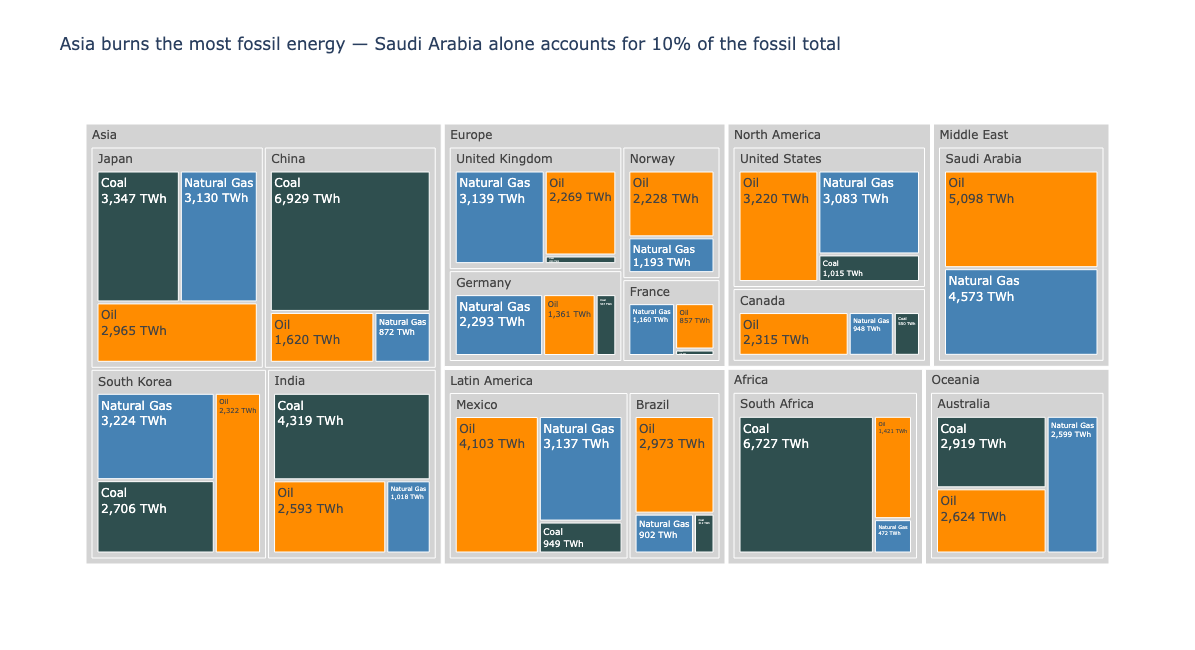

In [9]:
# Data prep
df_fossil = df.loc[df['Source_Type'] == 'Fossil'].copy()

top_region = df_fossil.groupby('Region')['TWh'].sum().idxmax()
country_totals = df_fossil.groupby('Country')['TWh'].sum()
top_country, top_share = country_totals.idxmax(), country_totals.max() / country_totals.sum()

# CVD-safe: dark charcoal / orange / blue 
fossil_colors = {'Coal': 'darkslategray', 'Oil': 'darkorange', 'Natural Gas': 'steelblue'}

# Step 1: Plotly Express base chart 
fig = px.treemap(
    df_fossil, path=['Region', 'Country', 'Source'], values='TWh',
    color='Source', color_discrete_map=fossil_colors,
    title=f'{top_region} burns the most fossil energy — {top_country} alone accounts for {top_share:.0%} of the fossil total',
    height=650, width=1100, template='plotly_white',
)

# Step 2: Customisation 
fig.update_traces(texttemplate='%{label}<br>%{value:,.0f} TWh',      # TWh values, no percentages
                  hovertemplate='%{label}: %{value:,.0f} TWh<extra></extra>')

# Grey out parent nodes (Region and Country level)
fig.data[0].marker.colors = [c if c in fossil_colors.values() else 'lightgrey' for c in fig.data[0].marker.colors]


fig.show()

## Task 2 — Treemap vs bar: low-carbon energy by country

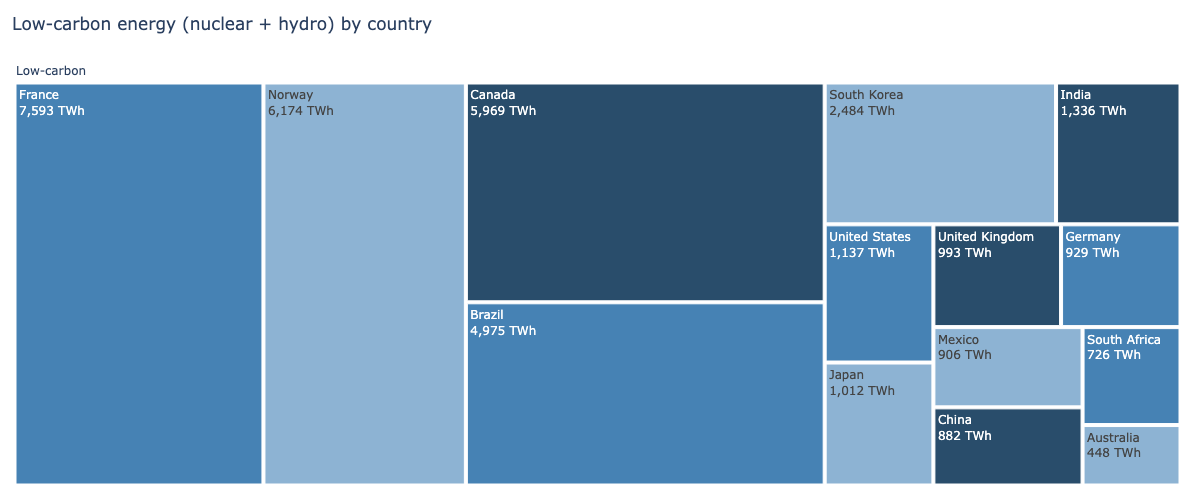

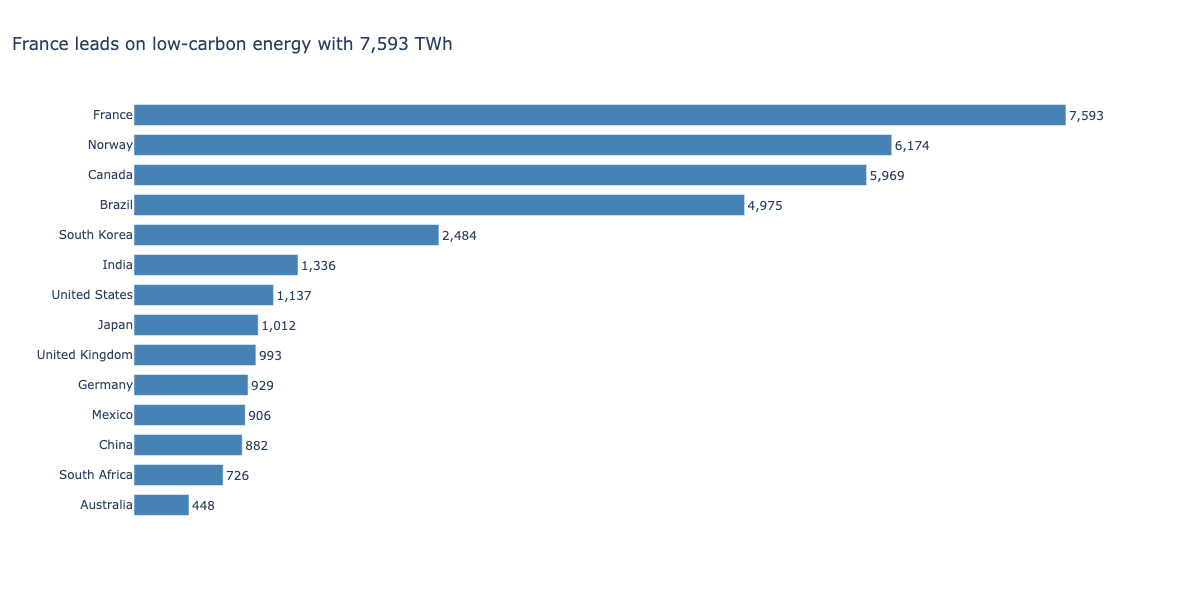

In [10]:
# Data prep
low_carbon = (df.loc[df['Source_Type'] == 'Low-carbon']
                .groupby('Country', as_index=False)['TWh'].sum()
                .sort_values('TWh', ascending=False))
low_carbon['All'] = 'Low-carbon'          # dummy root node (alternative: path=[px.Constant('Low-carbon'), 'Country'])

# Treemap 
fig_tree = px.treemap(low_carbon, path=['All', 'Country'], values='TWh',
                      color_discrete_sequence=['steelblue'],
                      title='Low-carbon energy (nuclear + hydro) by country',
                      height=500, width=1000, template='plotly_white')
fig_tree.update_traces(texttemplate='%{label}<br>%{value:,.0f} TWh',
                       hovertemplate='%{label}: %{value:,.0f} TWh<extra></extra>', root_color='white')
fig_tree.update_layout(title_x=0.01, margin=dict(l=10, r=10, t=60, b=10))
fig_tree.show()

#  Bar chart
leader = low_carbon.iloc[0]
fig_bar = px.bar(low_carbon, x='TWh', y='Country', orientation='h', text_auto=',.0f',
                 category_orders={'Country': low_carbon['Country'].tolist()},   # largest at the top
                 color_discrete_sequence=['steelblue'],
                 title=f"{leader['Country']} leads on low-carbon energy with {leader['TWh']:,.0f} TWh",
                 labels={'TWh': 'Low-carbon energy (TWh)', 'Country': ''},
                 height=600, width=1000, template='plotly_white')
fig_bar.update_traces(textposition='outside', hovertemplate='%{y}: %{x:,.0f} TWh<extra></extra>')
fig_bar.update_xaxes(visible=False)
fig_bar.update_layout(title_x=0.01, bargap=0.3)
fig_bar.show()

### Task 2 — reflection

**Which chart tells the ranking story more clearly, and why?**

The **bar chart**. Every bar starts from the same baseline, so the eye compares lengths directly and reads the ranking from top to bottom without effort. The treemap encodes value as **area**, which people judge far less accurately than length, and the rectangles are scattered across the canvas in a packing order rather than a ranking. The treemap is still useful for a quick impression of how dominant the leading countries are — and it becomes the better choice when the data has a hierarchy (e.g. Region → Country) that the reader needs to see.

## Task 3 — 100% stacked bar: which region relies most on coal?

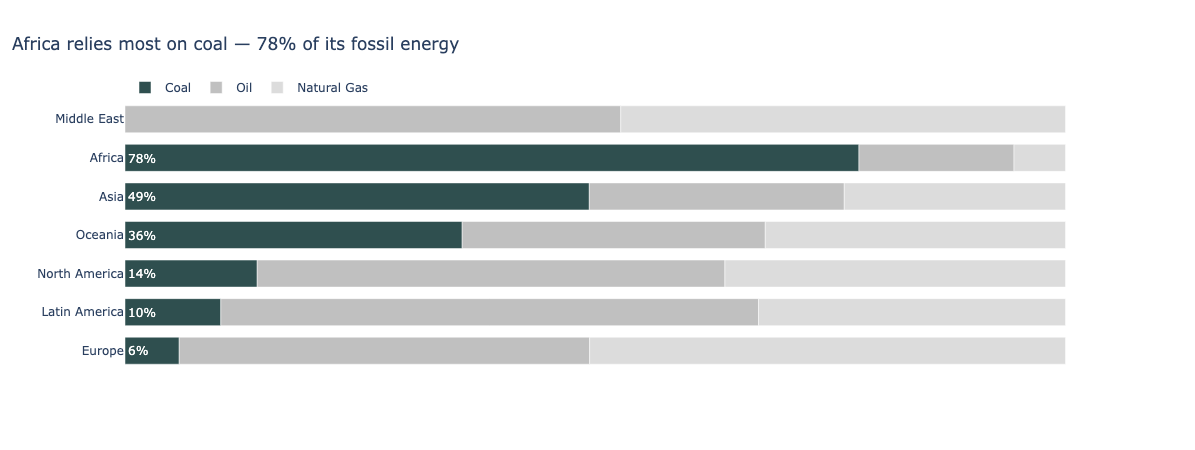

In [13]:
# ── Data prep ─────────────────────────────────────────────────────────────────
fossil_mix = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
fossil_mix['Share'] = fossil_mix['TWh'] / fossil_mix.groupby('Region')['TWh'].transform('sum')
fossil_mix['Label'] = np.where(fossil_mix['Source'] == 'Coal', fossil_mix['Share'].map('{:.0%}'.format), '')

coal = fossil_mix.loc[fossil_mix['Source'] == 'Coal'].sort_values('Share', ascending=False)

# Coal keeps its Task 1 colour; oil and gas become context greys
mix_colors = {'Coal': 'darkslategray', 'Oil': 'silver', 'Natural Gas': 'gainsboro'}

# ── Step 1: Plotly Express base chart ─────────────────────────────────────────
fig = px.bar(
    fossil_mix, x='Share', y='Region', color='Source', orientation='h', text='Label',
    color_discrete_map=mix_colors,
    category_orders={'Region': coal['Region'].tolist(),                  # highest coal share at the top
                     'Source': ['Coal', 'Oil', 'Natural Gas']},           # coal on the baseline
    title=f"{coal['Region'].iloc[0]} relies most on coal — {coal['Share'].iloc[0]:.0%} of its fossil energy",
    labels={'Region': '', 'Source': ''},
    height=450, width=950, template='plotly_white',
)

# ── Step 2: Customisation ─────────────────────────────────────────────────────
fig.update_traces(textposition='inside', insidetextanchor='start', textfont_color='white',
                  hovertemplate='%{y}, %{fullData.name}: %{x:.0%}<extra></extra>')
fig.update_xaxes(visible=False)
fig.update_yaxes(showgrid=False)
fig.update_layout(title_x=0.01, bargap=0.3, legend=dict(orientation='h', x=0, y=1.1))
fig.show()

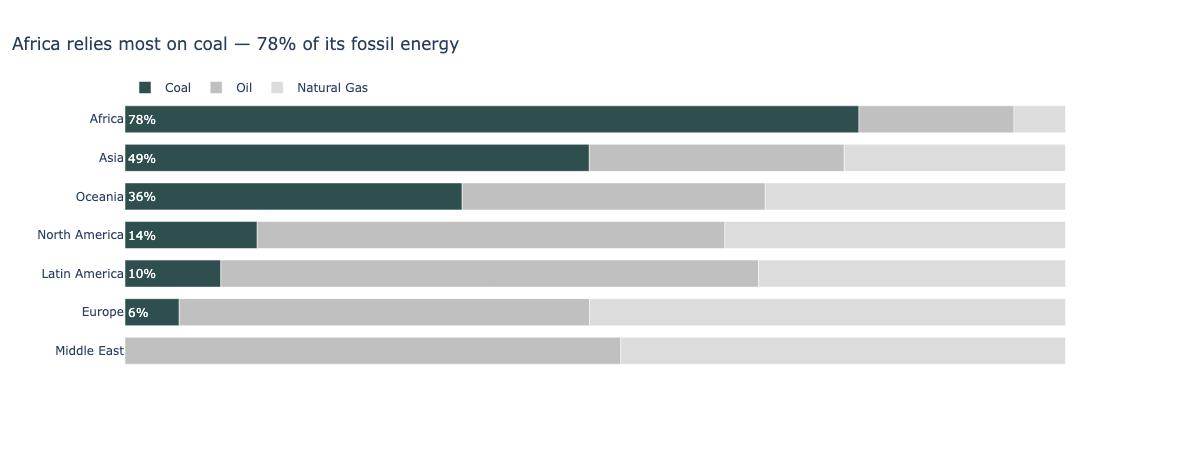

In [17]:
# Data prep 
fossil_mix = df_fossil.groupby(['Region', 'Source'], as_index=False)['TWh'].sum()
fossil_mix['Share'] = fossil_mix['TWh'] / fossil_mix.groupby('Region')['TWh'].transform('sum')
fossil_mix['Label'] = np.where(fossil_mix['Source'] == 'Coal', fossil_mix['Share'].map('{:.0%}'.format), '')

# Coal share for EVERY region — regions with no coal (e.g. Middle East) get 0 so they sort to the bottom
coal_share = (fossil_mix.loc[fossil_mix['Source'] == 'Coal']
                        .set_index('Region')['Share']
                        .reindex(fossil_mix['Region'].unique(), fill_value=0)
                        .sort_values(ascending=False))

# Coal keeps its Task 1 colour; oil and gas become context greys
mix_colors = {'Coal': 'darkslategray', 'Oil': 'silver', 'Natural Gas': 'gainsboro'}

# Step 1: Plotly Express base chart 
fig = px.bar(
    fossil_mix, x='Share', y='Region', color='Source', orientation='h', text='Label',
    color_discrete_map=mix_colors,
    category_orders={'Region': coal_share.index.tolist(),                # highest coal share at the top, no coal at the bottom
                     'Source': ['Coal', 'Oil', 'Natural Gas']},           # coal on the baseline
    title=f"{coal_share.index[0]} relies most on coal — {coal_share.iloc[0]:.0%} of its fossil energy",
    labels={'Region': '', 'Source': ''},
    height=450, width=950, template='plotly_white',
)

# Step 2: Customisation 
fig.update_traces(textposition='inside', insidetextanchor='start', textfont_color='white',
                  hovertemplate='%{y}, %{fullData.name}: %{x:.0%}<extra></extra>')
fig.update_xaxes(visible=False)
fig.update_yaxes(showgrid=False)
fig.update_layout(title_x=0.01, bargap=0.3, legend=dict(orientation='h', x=0, y=1.1))
fig.show()

### Task 3 — reflection

**Your Task 1 treemap and this stacked bar show the same fossil data. Name one question each chart answers that the other cannot.**

- **Treemap (Task 1):** *Which region and country burn the most fossil energy in absolute terms?* — the 100% stacked bar shows only shares, so a small region's bar is as long as the largest region's
- **Stacked bar (Task 3):** *Which region's fossil mix is most coal-heavy?* — in the treemap, the coal rectangles sit inside regions of very different sizes, so their proportions can't be compared by eye

Coal is placed **first**, so it is the only segment on the common baseline and its lengths can be compared directly across regions. Colouring only coal and greying oil and gas keeps the eye on the comparison the title makes, and coal keeps its Task 1 colour — colour should mean the same thing on every chart in a report.